# import

In [53]:
import pandas as pd

df = pd.read_csv('data/hard_testing_capture-2.csv')
df

,time_s,timestamp_ns,ch_0,ch_1,ch_2,ch_3,ch_4,ch_5,ch_6,ch_7,...,ch_66,ch_67,ch_68,ch_69,ch_70,ch_71,ch_72,ch_73,ch_74,ch_75
0,0.000000,17064193167943,17,27,-27,25,-7,-19,-47,18,...,-128,128,0,0,0,0,0,0,0,0
1,0.009514,17064202681828,81,51,50,40,76,78,81,101,...,-128,128,0,0,0,0,0,0,0,0
2,0.018854,17064212021862,3,-51,-32,-160,-18,-36,-17,-30,...,-128,128,0,0,0,0,0,0,0,0
3,0.028275,17064221443093,14,59,26,48,46,26,-4,26,...,-128,128,0,0,0,0,0,0,0,0
4,0.037656,17064230824428,0,-60,-47,-56,-68,-61,-26,-97,...,-128,128,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45359,436.889736,17501082903462,-77,-52,-17,-87,-1,-64,-98,-33,...,-128,128,0,0,0,0,0,0,0,0
45360,436.899275,17501092442919,-6,-5,28,11,13,15,44,-6,...,-128,128,0,0,0,0,0,0,0,0
45361,436.908952,17501102120343,37,30,-86,23,-147,57,75,74,...,-128,128,0,0,0,0,0,0,0,0
45362,436.918383,17501111551209,-13,-10,-25,-68,-28,-26,-10,-40,...,-128,128,0,0,0,0,0,0,0,0


In [54]:
features = df.loc[:, 'ch_0':'ch_63']
ground_truth = df.iloc[:, -12:]


Found 64 neural channels
Approximate fs: 103.823 Hz


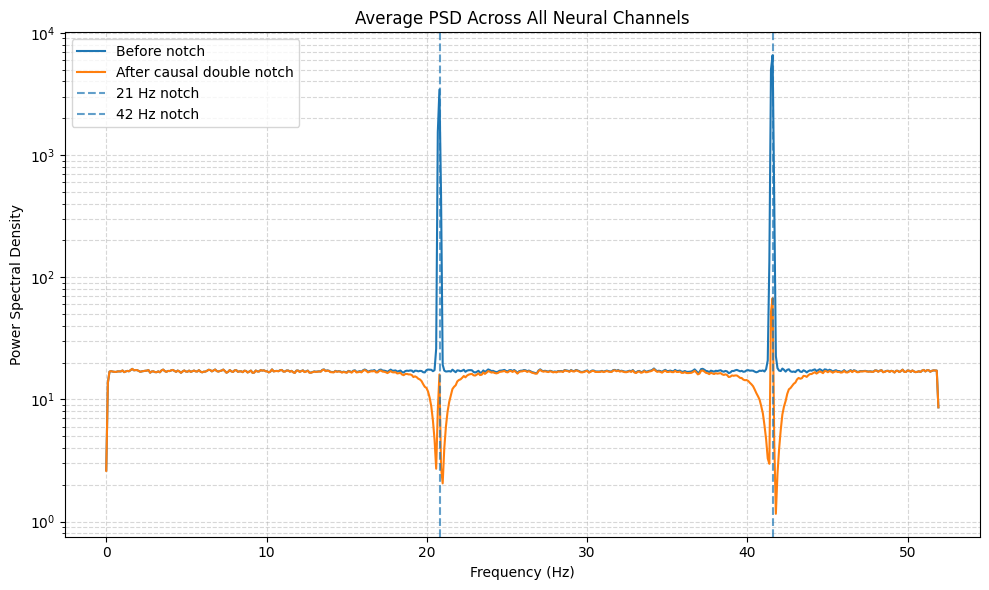

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, lfilter, welch

# --- settings ---
notch_freqs = [20.8, 41.6]   # two notch frequencies in Hz
Qs = [20, 30]             # Q for each notch
nperseg = 1024

# --- choose neural channels automatically ---
channels = [c for c in features.columns if c.startswith('ch_')]
print(f"Found {len(channels)} neural channels")

# crude fs estimate from timestamps
dt = np.mean(np.diff(df['time_s'].to_numpy()))
fs = 1.0 / dt
print(f"Approximate fs: {fs:.3f} Hz")

# --- design the two notch filters ---
filters = []
for notch_freq, Q in zip(notch_freqs, Qs):
    b, a = iirnotch(w0=notch_freq, Q=Q, fs=fs)
    filters.append((b, a))

# --- apply both notches causally to every channel ---
filtered_features = features.copy()

for ch in channels:
    x = features[ch].to_numpy().astype(float)
    y = x.copy()

    for b, a in filters:
        y = lfilter(b, a, y)   # causal sequential filtering

    filtered_features[ch] = y

# --- average PSD before and after across channels ---
psd_before = []
psd_after = []

for ch in channels:
    x = features[ch].to_numpy().astype(float)
    y = filtered_features[ch].to_numpy().astype(float)

    f, Pxx_before = welch(x, fs=fs, nperseg=nperseg)
    _, Pxx_after  = welch(y, fs=fs, nperseg=nperseg)

    psd_before.append(Pxx_before)
    psd_after.append(Pxx_after)

psd_before = np.array(psd_before)
psd_after = np.array(psd_after)

mean_psd_before = psd_before.mean(axis=0)
mean_psd_after = psd_after.mean(axis=0)

# --- plot PSDs ---
plt.figure(figsize=(10, 6))
plt.plot(f, mean_psd_before, label='Before notch')
plt.plot(f, mean_psd_after, label='After causal double notch')

for nf in notch_freqs:
    plt.axvline(nf, linestyle='--', alpha=0.7, label=f'{nf:.0f} Hz notch')

plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density')
plt.yscale('log')
plt.title('Average PSD Across All Neural Channels')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# button press model

In [56]:
# last 12 = original ground truth
ground_truth = df.iloc[:, -12:]

# last 8 = button channels
button_df = df.iloc[:, -8:]

# -------------------------
# if already 0/1:
# -------------------------
gt_button = (button_df.sum(axis=1) > 0).astype(int)


In [61]:
!pip install scikit-learn

In [67]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 21.0 MB/s  0:00:00


neural channels: 64
button channels: ['ch_68', 'ch_69', 'ch_70', 'ch_71', 'ch_72', 'ch_73', 'ch_74', 'ch_75']
uniform fs = 104.537 Hz
ch_68: 85 onsets, thresh=0.0000
ch_69: 85 onsets, thresh=0.0000
ch_70: 98 onsets, thresh=0.0000
ch_71: 124 onsets, thresh=0.0000
ch_72: 153 onsets, thresh=16383.5000
ch_73: 93 onsets, thresh=0.0000
ch_74: 94 onsets, thresh=0.0000
ch_75: 74 onsets, thresh=0.0000


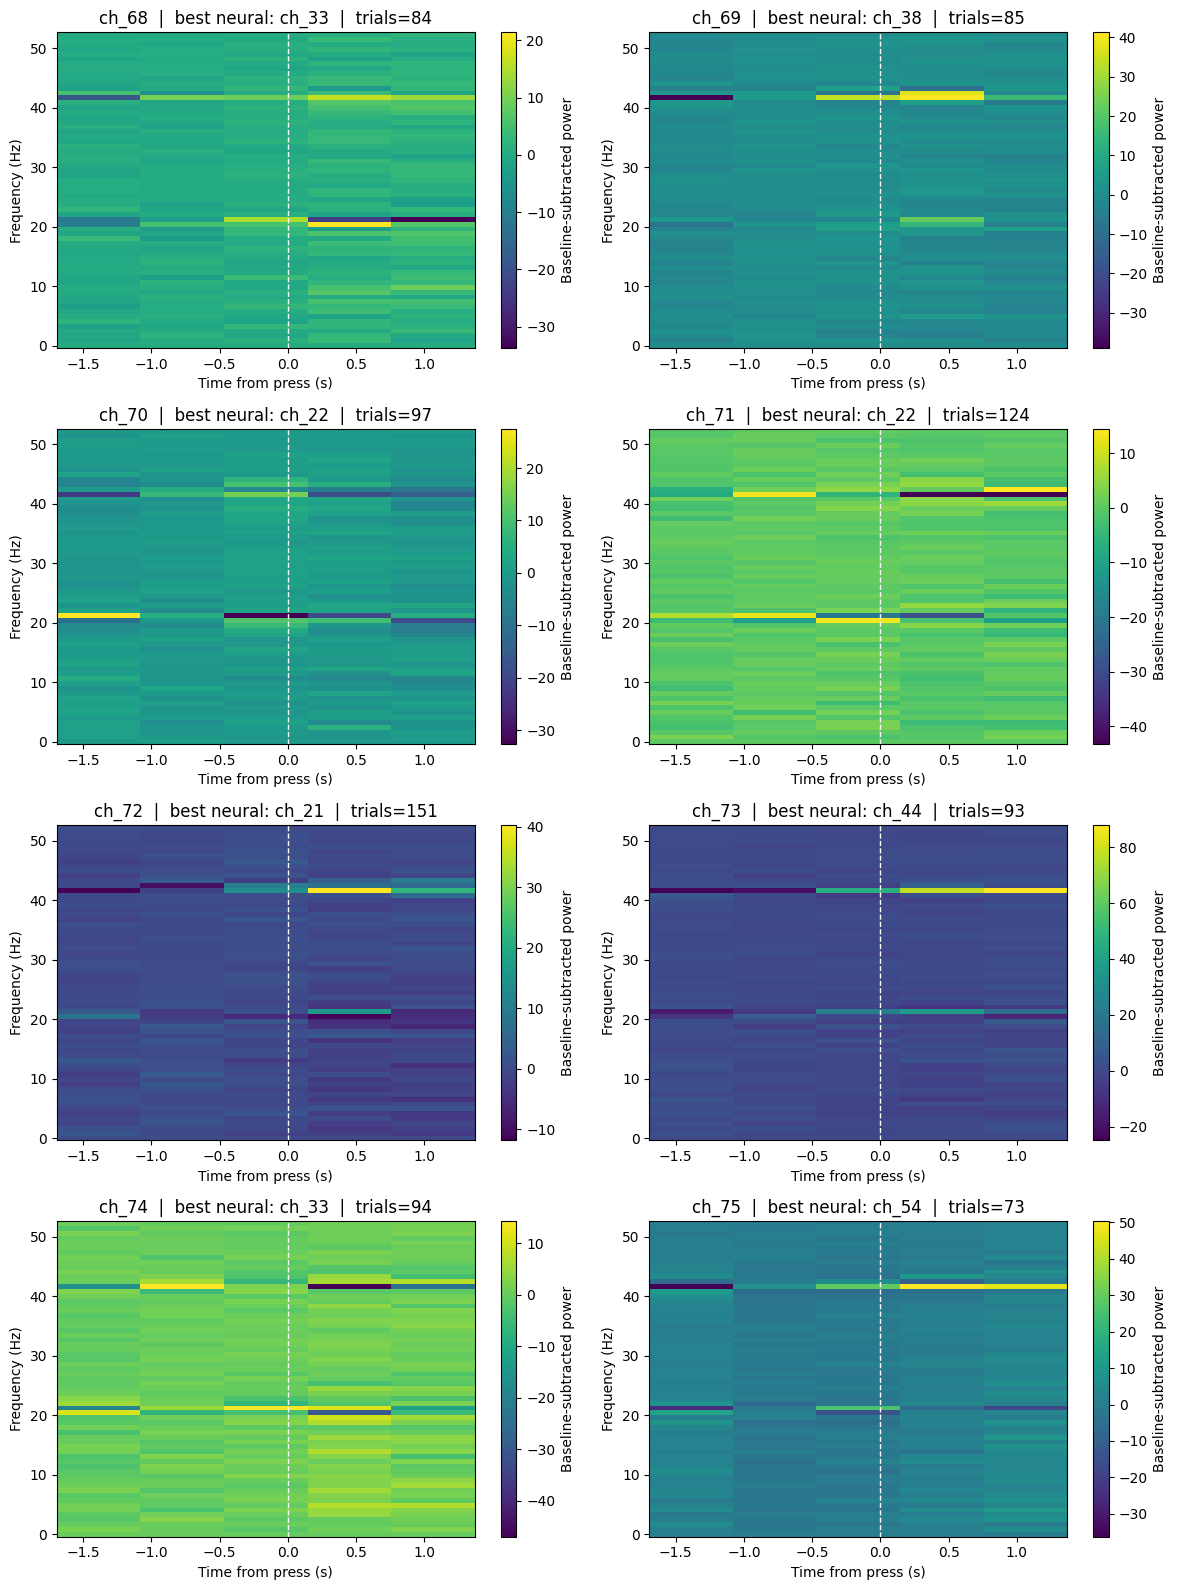

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import spectrogram
from scipy.interpolate import interp1d

# =========================================================
# 1) split channels
# =========================================================
all_ch = sorted(
    [c for c in df.columns if c.startswith('ch_')],
    key=lambda x: int(x.split('_')[1])
)

gt_cols = all_ch[-12:]
button_cols = gt_cols[-8:]     # last 8 truth channels = buttons
neural_cols = all_ch[:-12]

print("neural channels:", len(neural_cols))
print("button channels:", button_cols)

# =========================================================
# 2) resample to uniform time grid
#    spectrogram needs constant fs
# =========================================================
t = df["time_s"].to_numpy()
dt_med = np.median(np.diff(t))
fs = 1.0 / dt_med
t_uniform = np.arange(t[0], t[-1], dt_med)

def resample_to_uniform(x):
    f = interp1d(t, x, kind="linear", bounds_error=False, fill_value="extrapolate")
    return f(t_uniform)

neural = {ch: resample_to_uniform(df[ch].to_numpy()) for ch in neural_cols}
buttons = {ch: resample_to_uniform(df[ch].to_numpy()) for ch in button_cols}

print(f"uniform fs = {fs:.3f} Hz")

# =========================================================
# 3) detect button press onsets
#    threshold each button and find 0->1 transitions
# =========================================================
def detect_onsets(x, thresh=None, refractory_s=0.2):
    x = np.asarray(x)

    if thresh is None:
        # robust midpoint threshold
        xmin, xmax = np.nanpercentile(x, [5, 95])
        thresh = 0.5 * (xmin + xmax)

    binary = (x > thresh).astype(int)
    onsets = np.where((binary[1:] == 1) & (binary[:-1] == 0))[0] + 1

    # refractory pruning
    refractory = int(round(refractory_s * fs))
    if len(onsets) == 0:
        return onsets, binary, thresh

    keep = [onsets[0]]
    for idx in onsets[1:]:
        if idx - keep[-1] >= refractory:
            keep.append(idx)

    return np.array(keep), binary, thresh

button_onsets = {}
for b in button_cols:
    onsets, binary, thr = detect_onsets(buttons[b], thresh=None, refractory_s=0.2)
    button_onsets[b] = onsets
    print(f"{b}: {len(onsets)} onsets, thresh={thr:.4f}")

# =========================================================
# 4) parameters for event-related spectrograms
# =========================================================
pre_s = 2.0      # seconds before press
post_s = 2.0     # seconds after press

pre_n = int(round(pre_s * fs))
post_n = int(round(post_s * fs))
win_len = pre_n + post_n

# spectrogram params
nperseg = min(128, win_len)
noverlap = nperseg // 2
max_freq = min(150, fs / 2)

# =========================================================
# 5) helper: average baseline-corrected spectrogram
# =========================================================
def average_event_spectrogram(signal, onset_idx, fs, pre_n, post_n, nperseg=128, noverlap=64):
    """
    Returns:
        f_plot
        t_rel
        S_mean_bc     baseline-corrected mean spectrogram
        n_trials_used
    baseline correction: subtract mean pre-event power at each frequency
    """
    segments = []
    for ix in onset_idx:
        start = ix - pre_n
        end = ix + post_n
        if start >= 0 and end < len(signal):
            segments.append(signal[start:end])

    if len(segments) == 0:
        return None, None, None, 0

    S_trials = []
    f_plot = None
    t_rel = None

    for seg in segments:
        f, tt, Sxx = spectrogram(
            seg,
            fs=fs,
            nperseg=min(nperseg, len(seg)),
            noverlap=min(noverlap, max(0, min(nperseg, len(seg)) - 1)),
            scaling='density',
            mode='psd'
        )

        # keep frequency range
        keep_f = f <= max_freq
        f = f[keep_f]
        Sxx = Sxx[keep_f, :]

        # relative time axis, centered on button onset
        t_rel_local = tt - pre_n / fs

        # baseline subtract so pre-press = 0
        base_mask = t_rel_local < 0
        if not np.any(base_mask):
            continue

        baseline = Sxx[:, base_mask].mean(axis=1, keepdims=True)
        Sxx_bc = Sxx - baseline

        S_trials.append(Sxx_bc)
        f_plot = f
        t_rel = t_rel_local

    if len(S_trials) == 0:
        return None, None, None, 0

    S_mean_bc = np.mean(np.stack(S_trials, axis=0), axis=0)
    return f_plot, t_rel, S_mean_bc, len(S_trials)

# =========================================================
# 6) score all neural channels for each button
#    "greatest change" = mean absolute post-press baseline-corrected power
# =========================================================
best_for_button = {}

for b in button_cols:
    onsets = button_onsets[b]
    if len(onsets) == 0:
        best_for_button[b] = None
        continue

    scores = []

    for ch in neural_cols:
        f, t_rel, S_bc, n_used = average_event_spectrogram(
            neural[ch], onsets, fs, pre_n, post_n,
            nperseg=nperseg, noverlap=noverlap
        )

        if S_bc is None:
            continue

        post_mask = t_rel >= 0
        if not np.any(post_mask):
            continue

        score = np.mean(np.abs(S_bc[:, post_mask]))
        scores.append((ch, score, f, t_rel, S_bc, n_used))

    if len(scores) == 0:
        best_for_button[b] = None
        continue

    best_for_button[b] = max(scores, key=lambda x: x[1])

# =========================================================
# 7) plot only the strongest channel for each button
# =========================================================
valid_buttons = [b for b in button_cols if best_for_button[b] is not None]

nplots = len(valid_buttons)
ncols = 2
nrows = int(np.ceil(nplots / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows), squeeze=False)
axes = axes.flatten()

for ax, b in zip(axes, valid_buttons):
    ch, score, f, t_rel, S_bc, n_used = best_for_button[b]

    im = ax.pcolormesh(t_rel, f, S_bc, shading='auto')
    ax.axvline(0, color='w', linestyle='--', linewidth=1)
    ax.set_title(f"{b}  |  best neural: {ch}  |  trials={n_used}")
    ax.set_xlabel("Time from press (s)")
    ax.set_ylabel("Frequency (Hz)")
    fig.colorbar(im, ax=ax, label="Baseline-subtracted power")

for j in range(len(valid_buttons), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

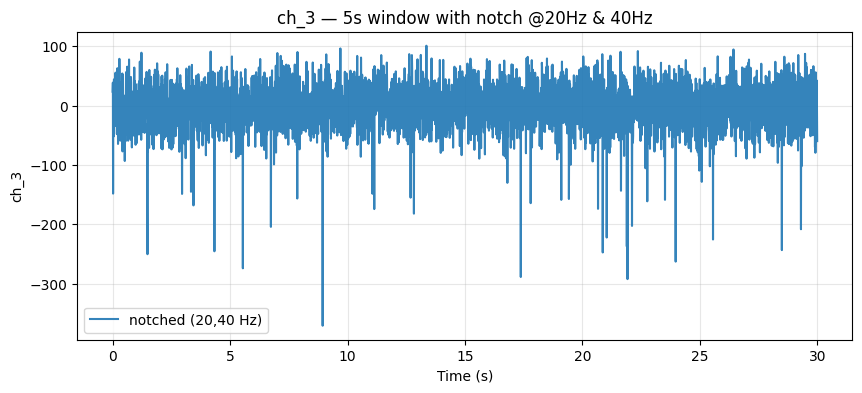

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, lfilter

ch = 'ch_3'
start_time = 0

t = df['time_s'].to_numpy()
x = df[ch].to_numpy()

# estimate fs
dt = np.median(np.diff(t))
fs = 1.0 / dt

# -------------------
# design notches
# -------------------
b20, a20 = iirnotch(w0=20.8, Q=30, fs=fs)
b40, a40 = iirnotch(w0=41, Q=30, fs=fs)

# -------------------
# apply causally
# -------------------
x_notched = lfilter(b20, a20, x)
x_notched = lfilter(b40, a40, x_notched)

# -------------------
# plot 5 seconds
# -------------------
mask = (t >= start_time) & (t <= start_time + 30)

plt.figure(figsize=(10,4))
plt.plot(t[mask], x_notched[mask], label='notched (20,40 Hz)', alpha=0.9)

plt.xlabel('Time (s)')
plt.ylabel(ch)
plt.title(f'{ch} — 5s window with notch @20Hz & 40Hz')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()